## Monte Carlo VaR and Expected Shortfall

- **Portfolio:** USD 5,000 — 50% AVGO, 25% QQQ, 15% MRVL and 10% TSLA
- **Time horizon:** 5 trading days
- **Lookback period:** 5 years
- **Confidence levels:** 90%, 95% and 99%
- **Number of simulations:** 100,000

The mean and standard deviation are estimated from historical rolling five-day portfolio returns. Based on the normal-distribution assumption, 100,000 five-day return scenarios are simulated. Monte Carlo VaR is estimated from the lower-tail percentiles of the simulated distribution, while Expected Shortfall is calculated as the average loss beyond each corresponding VaR threshold.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import norm

In [10]:
tickers = ["QQQ", "MRVL", "TSLA", "AVGO"]
weights = np.array([0.25, 0.15, 0.1, 0.5])
portfolio_value = 5000
time_horizon = 5 #in days

In [11]:
log_returns = pd.read_csv("cleaned_log_returns.csv", index_col="Date", parse_dates=True)
log_returns = log_returns.reindex(columns=tickers)
display(log_returns.head())

,QQQ,MRVL,TSLA,AVGO
Date,,,,
2021-11-15,-0.000228,-0.007650,-0.019573,0.004517
2021-11-16,0.007096,0.012267,0.039984,0.005289
2021-11-17,0.000528,-0.002441,0.031984,0.001529
2021-11-18,0.010308,0.020298,0.006745,0.009035
2021-11-19,0.005560,-0.007614,0.036432,-0.010651


In [12]:
portfolio_returns = log_returns.dot(weights)
portfolio_returns_5d =portfolio_returns.rolling(window=time_horizon).sum().dropna()
mean_5d = portfolio_returns_5d.mean()
std_5d = portfolio_returns_5d.std()

In [13]:
num_simulations = 100000
result_simulations = []
for i in range(num_simulations):
    returns = np.random.normal(mean_5d, std_5d)
    result_simulations.append(returns)

In [14]:
confidence_levels = [0.90, 0.95, 0.99]
VaR_values = []
ES_values = []

for confidence_level in confidence_levels:
    tail_percentile = (1 - confidence_level) * 100
    return_threshold = np.percentile(result_simulations,tail_percentile)
    result_simulations = np.array(result_simulations)
    tail_returns = result_simulations[result_simulations <= return_threshold]
    var = (-return_threshold * portfolio_value)
    es = (-np.mean(tail_returns) * portfolio_value)
    VaR_values.append(var)
    ES_values.append(es)
    print(f"{confidence_level:.0%} Monte Carlo VaR: ${var:,.2f}")
    print(f"{confidence_level:.0%} Monte Carlo ES: ${es:,.2f}")

90% Monte Carlo VaR: $299.69
90% Monte Carlo ES: $420.25
95% Monte Carlo VaR: $391.42
95% Monte Carlo ES: $499.16
99% Monte Carlo VaR: $571.73
99% Monte Carlo ES: $653.45


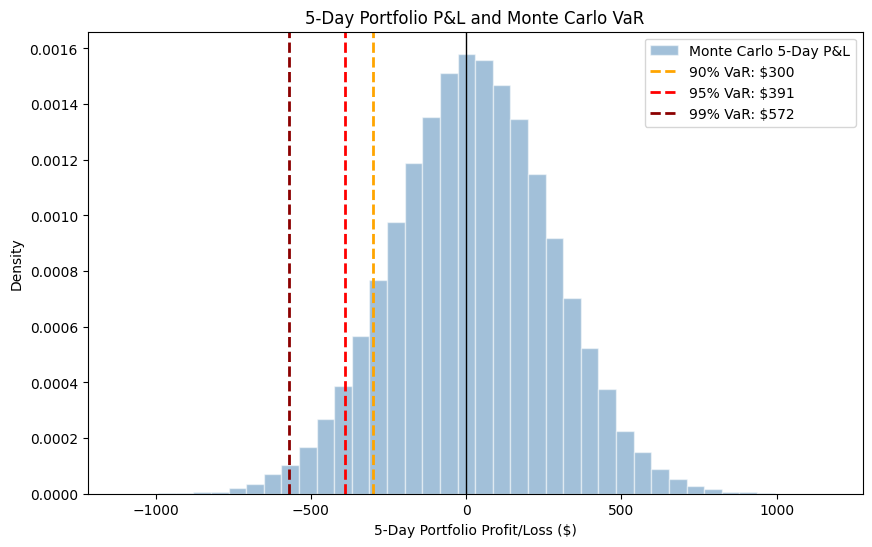

In [15]:
pnl_5d = np.array(result_simulations) * portfolio_value
plt.figure(figsize=(10, 6))
plt.hist(
    pnl_5d,
    bins=40,
    density=True,
    alpha=0.5,
    color="steelblue",
    edgecolor="white",
    label="Monte Carlo 5-Day P&L"
)

colors = ["orange", "red", "darkred"]
for confidence_level, var, color in zip(
    confidence_levels,
    VaR_values,
    colors
):
    plt.axvline(
        x=-var,
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{confidence_level:.0%} VaR: ${var:,.0f}"
    )
plt.axvline(x=0, color="black", linewidth=1)

plt.xlabel("5-Day Portfolio Profit/Loss ($)")
plt.ylabel("Density")
plt.title("5-Day Portfolio P&L and Monte Carlo VaR")
plt.legend()
plt.show()

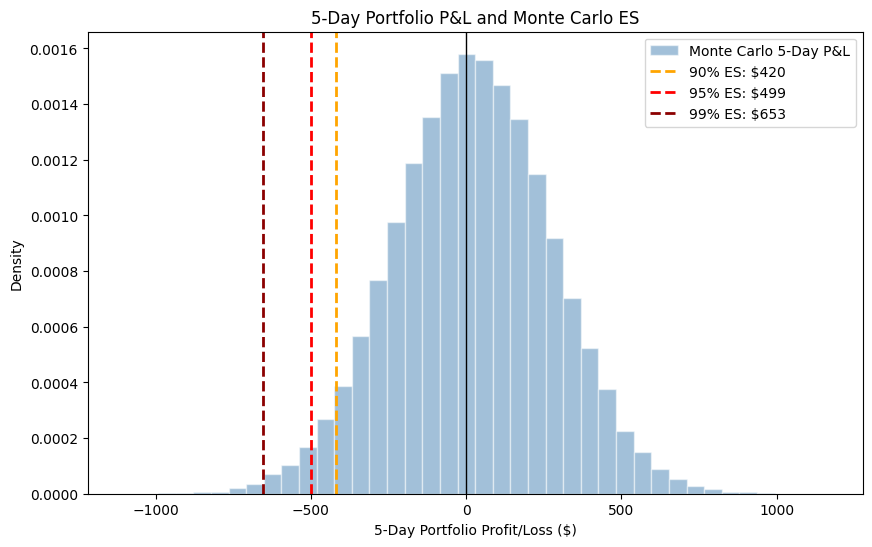

In [16]:
pnl_5d = np.array(result_simulations) * portfolio_value
plt.figure(figsize=(10, 6))
plt.hist(
    pnl_5d,
    bins=40,
    density=True,
    alpha=0.5,
    color="steelblue",
    edgecolor="white",
    label="Monte Carlo 5-Day P&L"
)

colors = ["orange", "red", "darkred"]
for confidence_level, es, color in zip(
    confidence_levels,
    ES_values,
    colors
):
    plt.axvline(
        x=-es,
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{confidence_level:.0%} ES: ${es:,.0f}"
    )
plt.axvline(x=0, color="black", linewidth=1)

plt.xlabel("5-Day Portfolio Profit/Loss ($)")
plt.ylabel("Density")
plt.title("5-Day Portfolio P&L and Monte Carlo ES")
plt.legend()
plt.show()